# CXAS: visualising saved results

The helpers in `cxas.visualize` draw selected structures from a saved `.npy` prediction (or directly from a prediction in memory). Class names can be single structures or groups from `cxas.label_mapper.label_mapper` (e.g. `all vertebrae`).

The example images come from the [NCI Imaging Data Commons](https://portal.imaging.datacommons.cancer.gov/) (CC BY): a PA + lateral pair of one patient from LIDC-IDRI and a portable AP film from COVID-19-NY-SBU. `demo_utils.get_example_images()` downloads them once into `example_data/` (needs `pip install idc-index`); sources and citations are in [`demo_utils.py`](demo_utils.py).

In [1]:
# !pip install cxas idc-index

In [2]:
import warnings; warnings.filterwarnings("ignore")
import transformers; transformers.utils.logging.disable_progress_bar()
import matplotlib.pyplot as plt; plt.rcParams["figure.dpi"] = 72
import torch
from demo_utils import get_example_images, display_image, overlay

DEVICE = "0" if torch.cuda.is_available() else "cpu"     # a GPU number, or "cpu"
paths = get_example_images()                              # downloads ~30 MB from the Imaging Data Commons once
paths

{'frontal_pa': 'example_data/frontal_pa.dcm',
 'lateral': 'example_data/lateral.dcm',
 'frontal_ap_portable': 'example_data/frontal_ap_portable.dcm',
 'frontal_pa_png': 'example_data/png/frontal_pa.png',
 'frontal_pa_jpg': 'example_data/jpg/frontal_pa.jpg',
 'dir': 'example_data'}

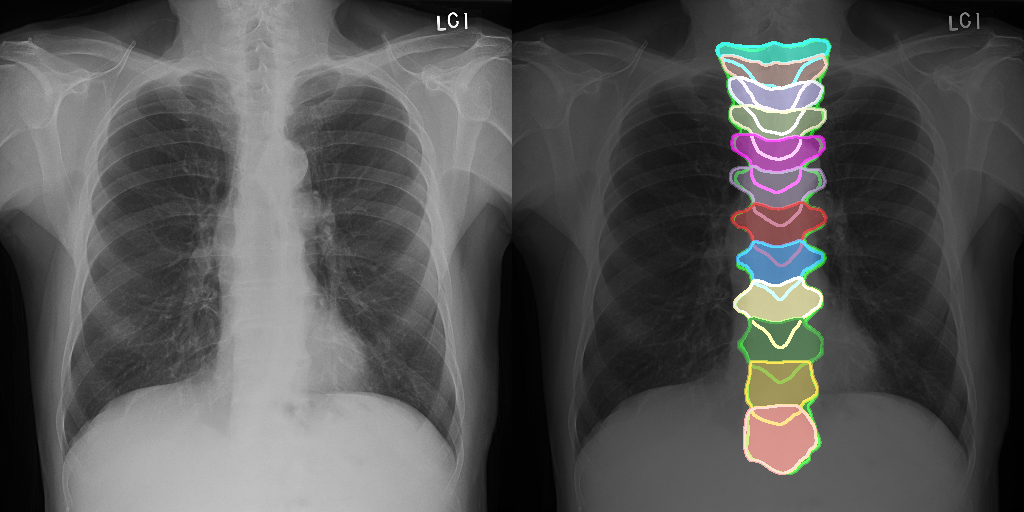

In [3]:
from cxas import CXAS
import cxas.visualize as cxas_vis

model = CXAS(model_name="M2F_anatomy_v2", gpus=DEVICE)
model.process_file(paths["frontal_pa_png"], do_store=True, output_directory="out/vis_npy", create=True, storage_type="npy")

cxas_vis.visualize_from_file(
    class_names=["thoracic spine"],
    img_path=paths["frontal_pa_png"],
    label_path="out/vis_npy/frontal_pa.npy",
    img_size=512,
    cat=True,            # image and overlay side by side
)

['frontal_pa_heart_right lung_left lung.png']


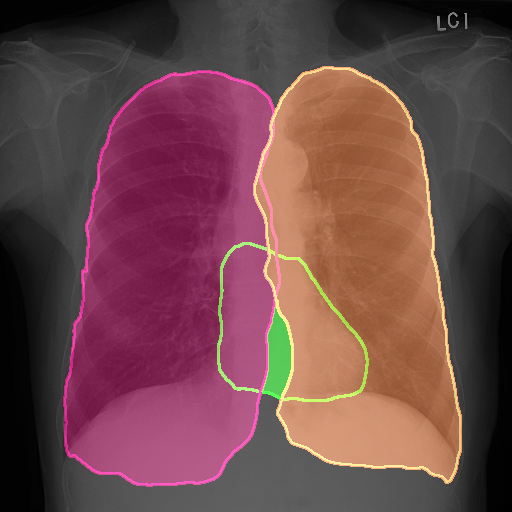

In [4]:
_ = cxas_vis.visualize_from_file(
    class_names=["heart", "right lung", "left lung"],
    img_path=paths["frontal_pa_png"],
    label_path="out/vis_npy/frontal_pa.npy",
    img_size=512,
    cat=False,
    do_store=True,
    out_dir="out/vis/",
)
import os
print(os.listdir("out/vis"))
_

Straight from a prediction, without saving it first:

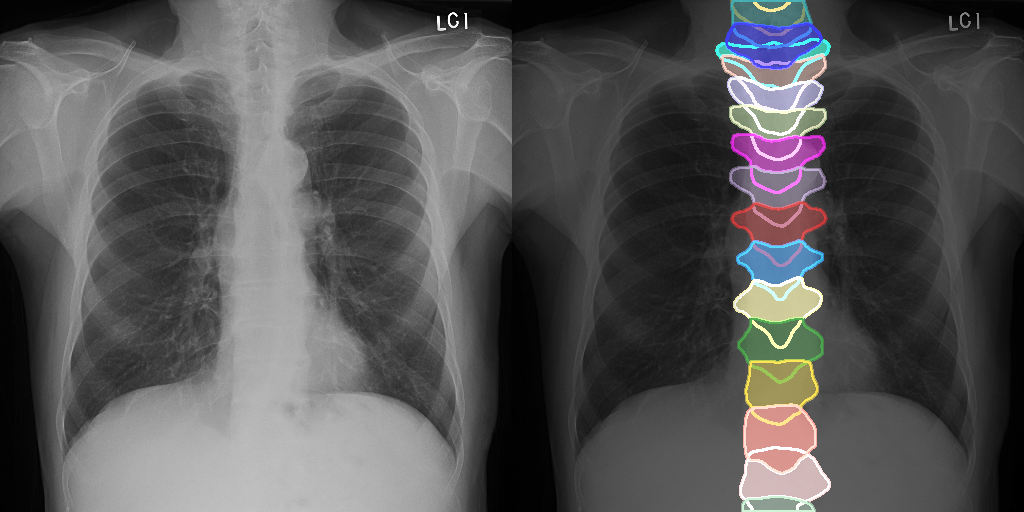

In [5]:
pred = model.process_file(paths["frontal_pa"])
cxas_vis.visualize_mask(
    class_names=["all vertebrae"],
    mask=pred["segmentation_preds"][0].cpu().numpy(),
    image=pred["orig_data"],
    img_size=512,
)